In [1]:
%pip install -q "qiskit==2.2.3" "qiskit-optimization==0.7.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-optimization", "numpy", "scipy", "torch", "matplotlib"]:
    print(name, version(name))
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
print("설치 및 import 확인 완료")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python: 3.13.18
qiskit 2.2.3
qiskit-optimization 0.7.0
numpy 2.1.3
scipy 1.16.3
torch 2.11.0+cpu
matplotlib 3.10.0
설치 및 import 확인 완료


[Epoch100] Val MSE:0.0623 WithinTol:75.12%
[Epoch200] Val MSE:0.0363 WithinTol:87.12%
[Epoch300] Val MSE:0.0315 WithinTol:90.12%
[Epoch400] Val MSE:0.0296 WithinTol:90.04%
[Epoch500] Val MSE:0.0278 WithinTol:90.96%
[Epoch600] Val MSE:0.0268 WithinTol:91.72%


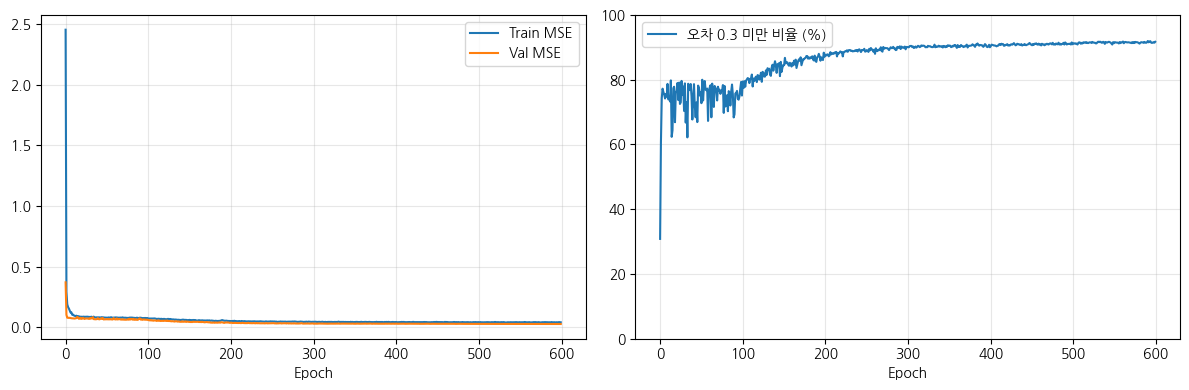

정확한 최솟값=44.047909, QAOA 후보 비용=44.047909, 차이=0.000000
유효 후보 관측 비율=0.3997, 최적 후보 관측 비율=0.3127

QAOA 기반 물류 라스트마일 최적 배송 결과
선택된 배송지: B_마포
예측 혼잡도: 2.75
총 비용: 44.05
QAOA 최소비용값(fval): 44.05


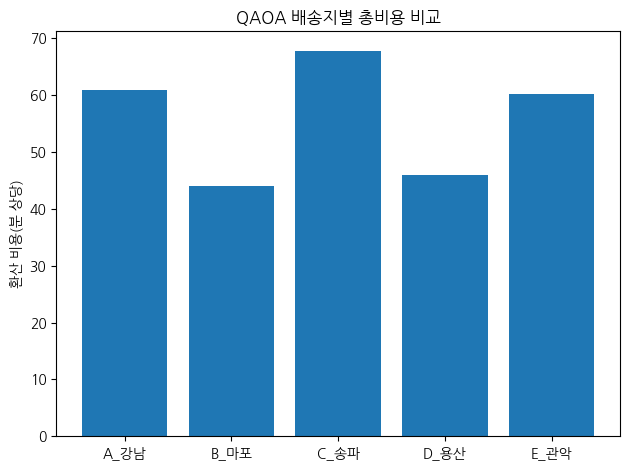

검증 MSE=0.026767, RMSE=0.163605, MAE=0.126138


In [8]:
from itertools import product
import numpy as np
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

def solve_checked(problem, reps=2, maxiter=100, seed=42):
    # 원문제의 제약을 유지한 채 내부 QUBO 변환과 역변환을 맡깁니다.
    qaoa = QAOA(
        sampler=StatevectorSampler(default_shots=4096, seed=seed),
        optimizer=COBYLA(maxiter=maxiter), reps=reps,
        initial_point=np.random.default_rng(seed).uniform(0.1, 1.0, 2*reps),
    )
    result = MinimumEigenOptimizer(qaoa).solve(problem)
    if result.x is None or not problem.is_feasible(result.x):
        raise RuntimeError("유효한 선택을 얻지 못했습니다. 샷·초깃값·탐색 예산을 바꿔 재실행하세요.")
    assert np.isclose(np.sum(result.x), 1)
    assert np.all(np.isclose(result.x, 0) | np.isclose(result.x, 1))
    assert np.isclose(result.fval, problem.objective.evaluate(result.x))
    feasible = [np.array(x) for x in product([0,1], repeat=problem.get_num_vars())
                if problem.is_feasible(np.array(x))]
    exact = min(float(problem.objective.evaluate(x)) for x in feasible)
    valid_mass = sum(float(s.probability) for s in result.samples if problem.is_feasible(s.x))
    best_mass = sum(float(s.probability) for s in result.samples
                    if problem.is_feasible(s.x) and np.isclose(s.fval, exact))
    gap = float(result.fval-exact)
    assert gap >= -1e-6 and np.isfinite(result.fval)
    assert np.isclose(sum(float(s.probability) for s in result.samples),1)
    print(f"정확한 최솟값={exact:.6f}, QAOA 후보 비용={result.fval:.6f}, 차이={gap:.6f}")
    print(f"유효 후보 관측 비율={valid_mass:.4f}, 최적 후보 관측 비율={best_mass:.4f}")
    return result

# ============================================
# QAOA 응용 4 - 물류 라스트마일 배송 최적화
# ============================================

import time

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

# -------------------------------------------
# 기본 설정
# -------------------------------------------
routes = ["A_강남", "B_마포", "C_송파", "D_용산", "E_관악"]
base_time = {"A_강남": 26, "B_마포": 19, "C_송파": 31, "D_용산": 22, "E_관악": 28}
base_dist = {"A_강남": 8.1, "B_마포": 5.3, "C_송파": 11.2, "D_용산": 6.5, "E_관악": 9.8}
base_park = {"A_강남": 3, "B_마포": 2, "C_송파": 2, "D_용산": 1, "E_관악": 3}
distance_weight = 1.0  # km당 환산분
alpha1, alpha2 = 5.0, 3.0  # 혼잡도·주차난도 1단계당 환산분

rng = np.random.default_rng(42)
torch.manual_seed(42)
torch.set_num_threads(1)

# -------------------------------------------
# 합성 데이터 생성
# -------------------------------------------
def simulate_congestion(hour, weekday, weather, accident):
    cong = np.array([2.5, 2.0, 3.0, 2.3, 1.8], dtype=float)
    if (7 <= hour <= 9) or (17 <= hour <= 19):
        cong += np.array([0.8, 0.6, 0.7, 0.5, 0.6])
    if weather == 1:
        cong += np.array([0.3, 0.2, 0.4, 0.1, 0.3])
    if accident == 1:
        cong += np.array([0.5, 0.2, 0.4, 0.3, 0.2])
    if weekday in [5,6]:
        cong -= np.array([0.2,0.1,0.3,0.2,0.1])
    cong += rng.normal(0,0.1,5)
    return np.clip(cong,1.0,4.0)

N = 2500
X = np.zeros((N,4)); Y = np.zeros((N,5))
for i in range(N):
    hour, weekday, weather, accident = rng.integers(0,24), rng.integers(0,7), rng.integers(0,2), rng.integers(0,2)
    X[i] = [hour, weekday, weather, accident]
    Y[i] = simulate_congestion(hour,weekday,weather,accident)
X[:,0]/=23; X[:,1]/=6
idx=np.arange(N); rng.shuffle(idx); cut=int(0.8*N)
Xtr,Ytr,Xva,Yva=X[idx[:cut]],Y[idx[:cut]],X[idx[cut:]],Y[idx[cut:]]

# -------------------------------------------
# PyTorch MLP
# -------------------------------------------
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4,32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32,16),
            nn.ReLU(),
            nn.Linear(16,5)
        )
    def forward(self,x): return self.net(x)

device = torch.device("cpu")
model = MLP().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = StepLR(optimizer, step_size=100, gamma=0.5)

train_loader = DataLoader(TensorDataset(torch.tensor(Xtr,dtype=torch.float32),torch.tensor(Ytr,dtype=torch.float32)),batch_size=64,shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(Xva,dtype=torch.float32),torch.tensor(Yva,dtype=torch.float32)),batch_size=256)

# -------------------------------------------
# 학습 루프
# -------------------------------------------
epochs=600
tr_mse,va_mse,va_acc=[],[],[]

def within_tolerance(y_true, y_pred, tol=0.3):
    diff = torch.abs(y_true - y_pred)
    within_tol = (diff < tol).float().mean().item()
    return within_tol * 100

for ep in range(1,epochs+1):
    model.train();loss_sum=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        pred=model(xb);loss=criterion(pred,yb)
        optimizer.zero_grad();loss.backward();optimizer.step()
        loss_sum+=loss.item()*xb.size(0)
    scheduler.step()
    tr_loss=loss_sum/len(train_loader.dataset);tr_mse.append(tr_loss)
    model.eval();v_loss,v_acc=0,0
    with torch.no_grad():
        for xb,yb in val_loader:
            xb,yb=xb.to(device),yb.to(device)
            pred=model(xb)
            v_loss+=criterion(pred,yb).item()*xb.size(0)
            v_acc+=within_tolerance(yb,pred)*xb.size(0)
    va_mse.append(v_loss/len(val_loader.dataset));va_acc.append(v_acc/len(val_loader.dataset))
    if ep%100==0: print(f"[Epoch{ep:3d}] Val MSE:{va_mse[-1]:.4f} WithinTol:{va_acc[-1]:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(tr_mse,label="Train MSE"); axes[0].plot(va_mse,label="Val MSE")
axes[1].plot(va_acc,label="오차 0.3 미만 비율 (%)"); axes[1].set_ylim(0,100)
for ax in axes: ax.legend(); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("training_performance_qaoa4.png")
plt.show(); plt.close()

# -------------------------------------------
# QAOA 부분
# -------------------------------------------
current = np.array([[9/23, 2/6, 1, 0]])  # 오전 9시, 수요일, 비, 사고 없음
with torch.no_grad():
    pred_cong = model(torch.tensor(current,dtype=torch.float32,device=device)).cpu().numpy().flatten()
pred_cong=np.clip(pred_cong,1.0,4.0)

costs={r:(distance_weight*base_dist[r]+base_time[r]+alpha1*c+alpha2*base_park[r]) for r,c in zip(routes,pred_cong)}

qaoa_reps, qaoa_maxiter = 3, 200

problem=QuadraticProgram()
for r in routes: problem.binary_var(r)
problem.linear_constraint({r:1 for r in routes},"==",1)
problem.minimize(linear=costs)
result = solve_checked(problem, reps=qaoa_reps, maxiter=qaoa_maxiter)

selected=[r for r,v in zip(routes,result.x) if v==1][0]
print("\n============================================")
print("QAOA 기반 물류 라스트마일 최적 배송 결과")
print("============================================")
print("선택된 배송지:",selected)
print("예측 혼잡도:",round(pred_cong[routes.index(selected)],2))
print("총 비용:",round(costs[selected],2))
print("QAOA 최소비용값(fval):",round(result.fval,2))
print("============================================")

plt.figure()
plt.bar(routes,[costs[r] for r in routes])
plt.title("QAOA 배송지별 총비용 비교")
plt.ylabel("환산 비용(분 상당)")
plt.tight_layout();plt.savefig("qaoa_delivery_result.png")
plt.show(); plt.close()

assert np.isfinite(tr_mse).all() and np.isfinite(va_mse).all()
assert tr_mse[-1] < tr_mse[0]
model.eval()
with torch.no_grad():
    check_pred = model(torch.tensor(Xva,dtype=torch.float32,device=device)).cpu().numpy()
assert check_pred.shape == Yva.shape and np.isfinite(check_pred).all()
rmse = float(np.sqrt(np.mean((check_pred-Yva)**2)))
mae = float(np.mean(np.abs(check_pred-Yva)))
print(f"검증 MSE={np.mean((check_pred-Yva)**2):.6f}, RMSE={rmse:.6f}, MAE={mae:.6f}")